# Trois ETF pour un même indice : lequel choisir ?

**Question :** trois ETF répliquent le STOXX Europe 600 — MEUD.PA (Amundi), EXSA.DE (iShares) et ETZ.PA (BNP Paribas Easy). Lequel un investisseur devrait-il retenir, et les écarts de performance entre eux s'expliquent-ils par leurs frais ?

## Plan

1. **Les trois ETF** : émetteur, frais courants, mode de réplication, politique de distribution.
2. **Données** : cours de clôture ajustés via yfinance, alignement des places de cotation, 660 séances communes du 19 février 2024 au 25 septembre 2026.
3. **Performance** : base 100 et rendement annualisé.
4. **Risque** : volatilité, drawdown maximal et ratio de Sharpe — trois fonds répliquant le même indice doivent porter le même risque.
5. **Qualité de réplication** : écart de performance observé comparé à l'écart de frais, puis tracking error.
6. **Conclusion et limites** : quel ETF retenir, et ce que les frais n'expliquent pas.

## Réponse attendue

MEUD.PA, le moins cher des trois, devrait offrir la meilleure performance pour un risque identique. L'écart d'EXSA.DE devrait s'expliquer par ses frais plus élevés ; celui d'ETZ.PA, plus large que ce que ses frais justifient, pourrait tenir à sa réplication synthétique.

*Hypothèse à vérifier dans la section 6.*

## 1. Les trois ETF

| ETF | Émetteur | Frais courants | Réplication | Dividendes |
|---|---|---|---|---|
| MEUD.PA | Amundi | 0,07 % | physique complète | capitalisés |
| EXSA.DE | iShares | 0,20 % | physique complète | distribués |
| ETZ.PA | BNP Paribas Easy | 0,19 % | synthétique (swap) | capitalisés |

## 2. Données

Cours de clôture quotidiens extraits de Yahoo Finance avec la bibliothèque `yfinance` fin septembre 2026, puis figés dans `data/etf_europe.csv` pour que les résultats restent reproductibles. Les cours sont ajustés des dividendes : sans cet ajustement, le détachement d'un dividende ferait apparaître une baisse de prix qui n'est pas une perte pour le porteur, et EXSA.DE, seul fonds distribuant, serait pénalisé face aux deux autres.

La fenêtre commence le 19 février 2024, premier jour coté de MEUD.PA sur Yahoo Finance après son changement d'émetteur : une comparaison de performance impose une période identique pour les trois fonds. Les séances où l'une des deux places de cotation, Paris ou Francfort, était fermée sont écartées.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# Load the frozen snapshot and keep only sessions common to the three funds
etf = pd.read_csv("../data/etf_europe.csv", index_col="Date", parse_dates=True)
etf = etf.dropna()

print(etf.index.min().date(), "->", etf.index.max().date(), "|", len(etf), "sessions")

2024-02-19 -> 2026-09-25 | 660 sessions


## 3. Performance

Les trois séries sont ramenées à 100 le 19 février 2024 : chaque courbe montre ce que sont devenus 100 € investis ce jour-là dans le fonds.

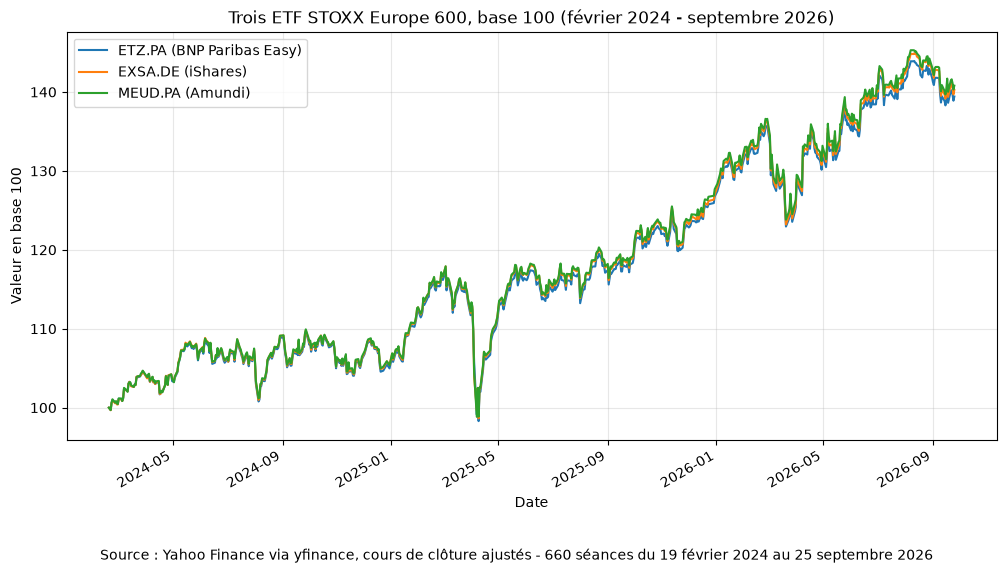

In [4]:
# Rebase the three funds to 100 on the first common session
base100 = etf / etf.iloc[0] * 100
labels = {"MEUD.PA": "MEUD.PA (Amundi)",
          "EXSA.DE": "EXSA.DE (iShares)",
          "ETZ.PA": "ETZ.PA (BNP Paribas Easy)"}

fig, ax = plt.subplots(figsize=(12, 6))
base100.rename(columns=labels).plot(ax=ax)
ax.set_title("Trois ETF STOXX Europe 600, base 100 (février 2024 - septembre 2026)")
ax.set_xlabel("Date")
ax.set_ylabel("Valeur en base 100")
ax.grid(alpha=0.3)
fig.text(0.5, 0, "Source : Yahoo Finance via yfinance, cours de clôture ajustés - 660 séances du 19 février 2024 au 25 septembre 2026", ha="center")
fig.savefig("../images/projet1_base100.png", dpi=150, bbox_inches="tight")

In [5]:
# Cumulative and annualized return over the full window
performance = etf.iloc[-1] / etf.iloc[0] - 1
n_years = (etf.index[-1] - etf.index[0]).days / 365.25
annualized = (1 + performance) ** (1 / n_years) - 1

perf = pd.DataFrame({"Performance cumulée": performance,
                     "Rendement annualisé": annualized})
perf = perf.sort_values("Performance cumulée", ascending=False)
perf.style.format("{:.2%}")

,Performance cumulée,Rendement annualisé
MEUD.PA,40.81%,14.08%
EXSA.DE,40.25%,13.90%
ETZ.PA,39.43%,13.65%


Les trois courbes sont presque superposées : sur deux ans et demi, elles traversent les mêmes hausses et le même creux d'avril 2025. L'écart n'apparaît que dans le tableau.

| ETF | Performance cumulée | Rendement annualisé |
|---|---|---|
| MEUD.PA | 40,81 % | 14,08 % |
| EXSA.DE | 40,25 % | 13,90 % |
| ETZ.PA | 39,43 % | 13,65 % |

MEUD.PA arrive en tête, ETZ.PA en dernier, avec 1,38 point d'écart cumulé entre les deux. Sur 10 000 € placés en février 2024, cela représente 138 € de moins pour le porteur d'ETZ.PA. Le classement suit celui des frais pour MEUD.PA et EXSA.DE, mais pas pour ETZ.PA, moins cher qu'EXSA.DE et pourtant derrière lui. La section 5 cherche d'où vient cet écart.

## 4. Risque

Trois mesures : la volatilité annualisée, qui décrit l'amplitude habituelle des variations ; le maximum drawdown, qui mesure la pire perte subie par un investisseur entré au plus haut ; le ratio de Sharpe, qui rapporte le rendement au-delà d'un taux sans risque de 2 % au risque pris.

In [6]:
# Daily returns, then annualized volatility (252 trading days)
returns = etf.pct_change().dropna()
volatility = returns.std() * 252 ** 0.5

# Drawdown from the running peak of the base 100 series
peaks = base100.cummax()
drawdown = (base100 - peaks) / peaks

# Sharpe ratio with a 2% risk-free rate, same assumption as notebook 08
rf = 0.02
sharpe = (annualized - rf) / volatility

risk = pd.DataFrame({"Volatilité annualisée": volatility,
                     "Maximum drawdown": drawdown.min(),
                     "Date du creux": drawdown.idxmin(),
                     "Sharpe (rf = 2 %)": sharpe})
risk.style.format({"Volatilité annualisée": "{:.2%}",
                   "Maximum drawdown": "{:.2%}",
                   "Date du creux": "{:%d/%m/%Y}",
                   "Sharpe (rf = 2 %)": "{:.2f}"})

,Volatilité annualisée,Maximum drawdown,Date du creux,Sharpe (rf = 2 %)
ETZ.PA,13.12%,-16.28%,09/04/2025,0.89
EXSA.DE,13.12%,-16.33%,09/04/2025,0.91
MEUD.PA,13.26%,-16.18%,07/04/2025,0.91


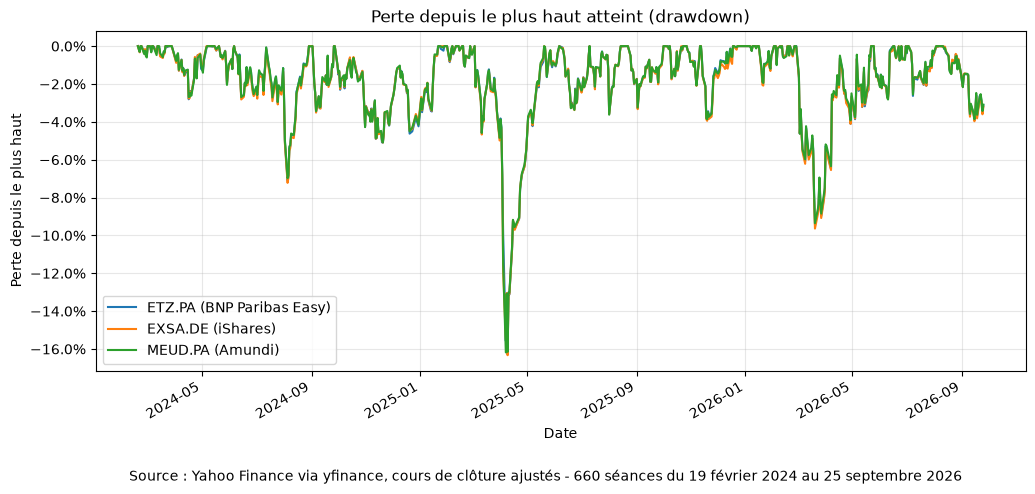

In [7]:
# Drawdown chart only: the base 100 chart is already in section 3
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(12, 5))
drawdown.rename(columns=labels).plot(ax=ax)
ax.set_title("Perte depuis le plus haut atteint (drawdown)")
ax.set_xlabel("Date")
ax.set_ylabel("Perte depuis le plus haut")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.grid(alpha=0.3)
fig.text(0.5, -0.02, "Source : Yahoo Finance via yfinance, cours de clôture ajustés - 660 séances du 19 février 2024 au 25 septembre 2026", ha="center")
fig.savefig("../images/projet1_drawdown.png", dpi=150, bbox_inches="tight")

Les trois fonds portent le même risque. Les volatilités tiennent dans 0,14 point (13,12 % à 13,26 %), les maximums drawdowns dans 0,15 point (−16,18 % à −16,33 %), et les trois creux tombent entre le 7 et le 9 avril 2025, lors du choc sur les droits de douane américains. Un même indice impose le même risque de marché : le gérant n'a aucune marge pour s'en écarter.

Un détail mérite d'être noté. Le 4 avril 2025, ETZ.PA affichait −9,95 % de drawdown quand les deux autres étaient déjà autour de −11,5 % et −11,9 %, et l'écart s'est refermé dès le lendemain. Par fort stress, les cours de clôture de fonds répliquant le même indice peuvent diverger de près de deux points, le temps que la liquidité revienne.

Le risque ne départage donc pas les trois fonds. Les ratios de Sharpe reproduisent le classement des rendements : le choix se joue sur le coût et la qualité de réplication, objet de la section 5.

## 5. Qualité de réplication

Les trois fonds suivent le même indice et portent le même risque. S'ils répliquaient parfaitement, leurs performances ne différeraient que de leurs frais. Cette section mesure ce qui reste une fois les frais déduits.

MEUD.PA sert de référence : c'est le fonds le moins cher, en réplication physique complète, et le fichier ne contient pas l'indice lui-même.

In [8]:
# Gap to MEUD.PA versus the gap explained by ongoing charges over the period
fees = pd.Series({"MEUD.PA": 0.0007, "EXSA.DE": 0.0020, "ETZ.PA": 0.0019})

gap = performance["MEUD.PA"] - performance
fee_gap = (fees - fees["MEUD.PA"]) * n_years
unexplained = gap - fee_gap

replication = pd.DataFrame({"Frais annuels": fees,
                            "Écart observé avec MEUD.PA": gap,
                            "Écart dû aux frais": fee_gap,
                            "Part non expliquée": unexplained}).drop("MEUD.PA")
replication.style.format("{:.2%}")

,Frais annuels,Écart observé avec MEUD.PA,Écart dû aux frais,Part non expliquée
ETZ.PA,0.19%,1.38%,0.31%,1.07%
EXSA.DE,0.20%,0.56%,0.34%,0.22%


In [9]:
# Tracking error: annualized volatility of daily return differences with MEUD.PA
diff = returns.sub(returns["MEUD.PA"], axis=0).drop(columns="MEUD.PA")
tracking_error = diff.std() * 252 ** 0.5
tracking_error.to_frame("Tracking error vs MEUD.PA").style.format("{:.2%}")

,Tracking error vs MEUD.PA
ETZ.PA,1.62%
EXSA.DE,1.40%


Les deux mesures ne disent pas la même chose. L'écart de performance est un résultat final : combien le porteur a gagné en moins sur la période. La tracking error mesure la régularité du suivi, jour après jour : un fonds peut finir proche de la référence tout en s'en écartant souvent en cours de route.

Pour EXSA.DE, les frais expliquent l'essentiel de l'écart : il ne reste que 0,22 point, un niveau qu'un décalage d'horaire de clôture entre Francfort et Paris ou un prêt de titres différent suffit à produire.

Pour ETZ.PA, les frais n'expliquent que 0,31 point sur 1,38. Il reste 1,07 point. Les tracking errors, elles, sont proches : 1,62 % pour ETZ.PA, 1,40 % pour EXSA.DE. ETZ.PA ne suit donc pas MEUD.PA de façon plus irrégulière ; il perd un peu chaque jour, de façon régulière. Ce profil correspond à un coût permanent non inclus dans les frais courants. ETZ.PA est le seul fonds synthétique des trois : il détient un panier d'actions qui n'est pas celui de l'indice et reçoit la performance de l'indice via un swap, dont le coût est une explication plausible. Les données disponibles ne permettent pas de la confirmer : il faudrait les rapports annuels du fonds.

Une réserve sur ces tracking errors : elles sont calculées sur les cours de clôture en bourse, pas sur les valeurs liquidatives publiées par les sociétés de gestion. Elles incluent donc le bruit de cotation (fourchettes, horaires et places différents), ce qui explique leur niveau élevé pour des fonds qui suivent le même indice.

## 6. Conclusion et limites

**MEUD.PA est le fonds à retenir.** Sur la période, il affiche la meilleure performance (40,81 %, soit 14,08 % par an), pour un risque identique à celui des deux autres et les frais les plus bas (0,07 %).

Les trois fonds portent le même risque de marché : volatilités entre 13,12 % et 13,26 %, maximums drawdowns entre −16,18 % et −16,33 %. Le choix se joue donc ailleurs. Pour EXSA.DE, les frais expliquent l'essentiel de l'écart avec MEUD.PA ; il ne reste que 0,22 point. Pour ETZ.PA, il reste 1,07 point que les frais n'expliquent pas, perdu de façon régulière et non par à-coups.

La réponse attendue est confirmée en partie. Le classement et le rôle des frais le sont. L'hypothèse d'un coût lié à la réplication synthétique d'ETZ.PA reste plausible, mais ces données ne suffisent pas à la prouver.

**Limites**

- MEUD.PA sert de référence faute de données sur l'indice : les écarts sont mesurés entre fonds, pas face au STOXX Europe 600 lui-même.
- La tracking error est calculée sur les cours de bourse, pas sur les valeurs liquidatives : elle inclut le bruit de cotation.
- L'écart dû aux frais est approché de façon linéaire (frais × années), sans composition.
- La fenêtre couvre 2,6 ans et un seul choc majeur, en avril 2025.
- Plusieurs critères de choix ne sont pas étudiés : liquidité, fourchette achat-vente, encours du fonds, fiscalité des dividendes.

**Pour aller plus loin**

Les rapports annuels d'ETZ.PA, qui détaillent le coût du swap, et les valeurs liquidatives publiées par les trois sociétés de gestion permettraient de confirmer ou d'écarter l'hypothèse.